In [3]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler


from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN


from sklearn.metrics import silhouette_score


from scipy.cluster.hierarchy import dendrogram, linkage

# Ignore warnings
import warnings
warnings.filterwarnings('ignore')

In [4]:
df = pd.read_csv("Clustering_Marketing.csv")

In [5]:
df.head()

,gradyear,gender,age,NumberOffriends,basketball,football,soccer,softball,volleyball,swimming,...,blonde,mall,shopping,clothes,hollister,abercrombie,die,death,drunk,drugs
0,2007,NaN,NaN,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,2007,F,17.41,49,0,0,1,0,0,1,...,0,0,0,0,0,0,0,0,1,0
2,2007,F,17.511,41,0,0,0,0,0,0,...,0,1,0,0,0,0,0,0,1,1
3,2006,F,NaN,36,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,2008,F,16.657,1,0,0,0,0,0,1,...,0,0,0,3,0,0,0,0,0,0


In [6]:
df.shape

(15000, 40)

In [7]:
df.head()

,gradyear,gender,age,NumberOffriends,basketball,football,soccer,softball,volleyball,swimming,...,blonde,mall,shopping,clothes,hollister,abercrombie,die,death,drunk,drugs
0,2007,NaN,NaN,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,2007,F,17.41,49,0,0,1,0,0,1,...,0,0,0,0,0,0,0,0,1,0
2,2007,F,17.511,41,0,0,0,0,0,0,...,0,1,0,0,0,0,0,0,1,1
3,2006,F,NaN,36,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,2008,F,16.657,1,0,0,0,0,0,1,...,0,0,0,3,0,0,0,0,0,0


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 40 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   gradyear         15000 non-null  int64
 1   gender           13663 non-null  str  
 2   age              12504 non-null  str  
 3   NumberOffriends  15000 non-null  int64
 4   basketball       15000 non-null  int64
 5   football         15000 non-null  int64
 6   soccer           15000 non-null  int64
 7   softball         15000 non-null  int64
 8   volleyball       15000 non-null  int64
 9   swimming         15000 non-null  int64
 10  cheerleading     15000 non-null  int64
 11  baseball         15000 non-null  int64
 12  tennis           15000 non-null  int64
 13  sports           15000 non-null  int64
 14  cute             15000 non-null  int64
 15  sex              15000 non-null  int64
 16  sexy             15000 non-null  int64
 17  hot              15000 non-null  int64
 18  kissed           

In [9]:
df.describe()

,gradyear,NumberOffriends,basketball,football,soccer,softball,volleyball,swimming,cheerleading,baseball,...,blonde,mall,shopping,clothes,hollister,abercrombie,die,death,drunk,drugs
count,15000.000000,15000.000000,15000.000000,15000.000000,15000.00000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,...,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,2007.496933,29.834533,0.267000,0.255467,0.22200,0.159667,0.142933,0.135000,0.105133,0.104133,...,0.112867,0.259467,0.357267,0.150267,0.071800,0.051467,0.185867,0.118067,0.091733,0.061067
std,1.116516,35.386649,0.788851,0.702260,0.92042,0.737344,0.638747,0.548691,0.502491,0.519205,...,2.708619,0.704398,0.728512,0.478716,0.356258,0.280755,0.609928,0.455200,0.420631,0.349112
min,2006.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2006.000000,3.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,2008.000000,20.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,2008.000000,44.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,2009.000000,605.000000,22.000000,9.000000,22.00000,17.000000,14.000000,31.000000,8.000000,14.000000,...,327.000000,12.000000,11.000000,8.000000,8.000000,8.000000,16.000000,14.000000,8.000000,16.000000


In [10]:
df.columns

Index(['gradyear', 'gender', 'age', 'NumberOffriends', 'basketball',
       'football', 'soccer', 'softball', 'volleyball', 'swimming',
       'cheerleading', 'baseball', 'tennis', 'sports', 'cute', 'sex', 'sexy',
       'hot', 'kissed', 'dance', 'band', 'marching', 'music', 'rock', 'god',
       'church', 'jesus', 'bible', 'hair', 'dress', 'blonde', 'mall',
       'shopping', 'clothes', 'hollister', 'abercrombie', 'die', 'death',
       'drunk', 'drugs'],
      dtype='str')

In [11]:
df.dtypes

gradyear           int64
gender               str
age                  str
NumberOffriends    int64
basketball         int64
football           int64
soccer             int64
softball           int64
volleyball         int64
swimming           int64
cheerleading       int64
baseball           int64
tennis             int64
sports             int64
cute               int64
sex                int64
sexy               int64
hot                int64
kissed             int64
dance              int64
band               int64
marching           int64
music              int64
rock               int64
god                int64
church             int64
jesus              int64
bible              int64
hair               int64
dress              int64
blonde             int64
mall               int64
shopping           int64
clothes            int64
hollister          int64
abercrombie        int64
die                int64
death              int64
drunk              int64
drugs              int64


In [12]:
print(df['gender'].unique())
print(df['age'].unique())

<ArrowStringArray>
[nan, 'F', 'M']
Length: 3, dtype: str
<ArrowStringArray>
[      nan,   '17.41',  '17.511',  '16.657',  '18.034',   '18.53',  '19.168',
  '18.535',   '16.83',  '17.697',
 ...
  '20.638',  '19.474',   '21.64',  '19.291',  '19.548',  '19.535',  '12.392',
   '8.498',  '19.975', '106.511']
Length: 1907, dtype: str


In [13]:
df.isnull().sum()

gradyear              0
gender             1337
age                2496
NumberOffriends       0
basketball            0
football              0
soccer                0
softball              0
volleyball            0
swimming              0
cheerleading          0
baseball              0
tennis                0
sports                0
cute                  0
sex                   0
sexy                  0
hot                   0
kissed                0
dance                 0
band                  0
marching              0
music                 0
rock                  0
god                   0
church                0
jesus                 0
bible                 0
hair                  0
dress                 0
blonde                0
mall                  0
shopping              0
clothes               0
hollister             0
abercrombie           0
die                   0
death                 0
drunk                 0
drugs                 0
dtype: int64

In [14]:
df.isnull().sum()[df.isnull().sum() > 0]

gender    1337
age       2496
dtype: int64

In [15]:
df['gender'].value_counts(dropna=False)

gender
F      11057
M       2606
NaN     1337
Name: count, dtype: int64

In [16]:
print(df['gender'].unique())
print(df['age'].unique())
df.isnull().sum()[df.isnull().sum() > 0]

<ArrowStringArray>
[nan, 'F', 'M']
Length: 3, dtype: str
<ArrowStringArray>
[      nan,   '17.41',  '17.511',  '16.657',  '18.034',   '18.53',  '19.168',
  '18.535',   '16.83',  '17.697',
 ...
  '20.638',  '19.474',   '21.64',  '19.291',  '19.548',  '19.535',  '12.392',
   '8.498',  '19.975', '106.511']
Length: 1907, dtype: str


gender    1337
age       2496
dtype: int64

In [17]:
df['age'] = pd.to_numeric(df['age'], errors='coerce')

In [18]:
df['age'].dtype

dtype('float64')

In [19]:
df['age'].describe()

count    12228.000000
mean        17.988164
std          7.715857
min          4.309000
25%         16.331000
50%         17.295000
75%         18.264000
max        106.927000
Name: age, dtype: float64

In [20]:
print("Minimum age:", df['age'].min())
print("Maximum age:", df['age'].max())

Minimum age: 4.309
Maximum age: 106.927


In [21]:
df.loc[(df['age'] < 13) | (df['age'] > 30), 'age'] = np.nan

In [22]:
df['age'].describe()

count    12084.000000
mean        17.285270
std          1.213003
min         13.027000
25%         16.326000
50%         17.281000
75%         18.242750
max         29.796000
Name: age, dtype: float64

In [23]:
df['age'].isnull().sum()

np.int64(2916)

In [24]:
df['age'] = df['age'].fillna(df['age'].median())

In [25]:
df['age'].describe()

count    15000.000000
mean        17.284440
std          1.088726
min         13.027000
25%         16.550000
50%         17.281000
75%         18.012000
max         29.796000
Name: age, dtype: float64

In [26]:
df['age'].isnull().sum()

np.int64(0)

In [27]:
df['gender'] = df['gender'].fillna('Unknown')

In [28]:
df['gender'].value_counts()

gender
F          11057
M           2606
Unknown     1337
Name: count, dtype: int64

In [29]:
df.isnull().sum()[df.isnull().sum() > 0]

Series([], dtype: int64)

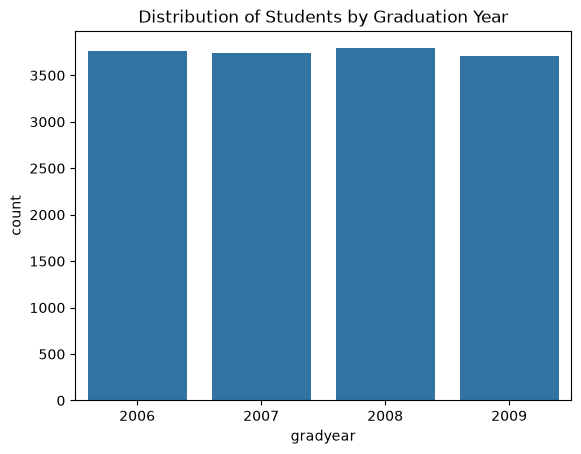

In [30]:
# Graduation year distribution
sns.countplot(x='gradyear', data=df)
plt.title('Distribution of Students by Graduation Year')
plt.show()

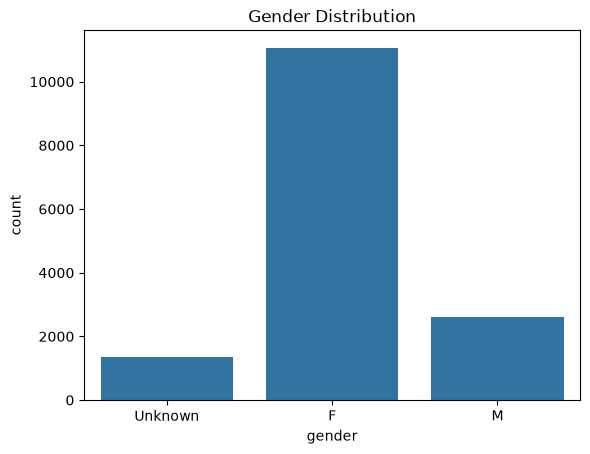

In [31]:
# Gender distribution
sns.countplot(x='gender', data=df)
plt.title('Gender Distribution')
plt.show()

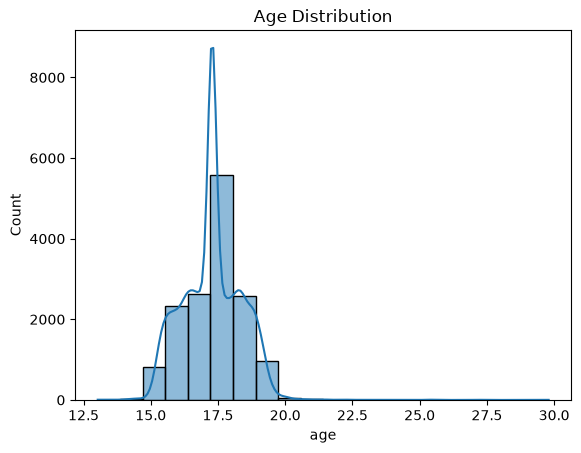

In [32]:
# Age distribution
sns.histplot(df['age'], bins=20, kde=True)
plt.title('Age Distribution')
plt.show()

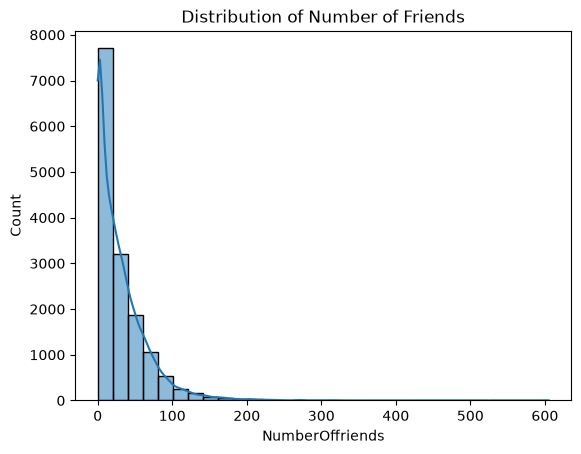

In [33]:
# Number of friends distribution
sns.histplot(df['NumberOffriends'], bins=30, kde=True)
plt.title('Distribution of Number of Friends')
plt.show()

Graduation year: students are distributed quite evenly across 2006–2009.
Gender: the dataset is strongly female-dominated; keeping missing gender as Unknown was sensible.
Age: after cleaning, most students are concentrated around 15–19 years, with a large spike around the median because we imputed missing ages with the median.
NumberOfFriends: this is strongly right-skewed. Most students have relatively few friends, while a small number have very large friend counts. This will likely need transformation before clustering.

In [34]:
interest_cols = df.columns[4:]

interest_cols

Index(['basketball', 'football', 'soccer', 'softball', 'volleyball',
       'swimming', 'cheerleading', 'baseball', 'tennis', 'sports', 'cute',
       'sex', 'sexy', 'hot', 'kissed', 'dance', 'band', 'marching', 'music',
       'rock', 'god', 'church', 'jesus', 'bible', 'hair', 'dress', 'blonde',
       'mall', 'shopping', 'clothes', 'hollister', 'abercrombie', 'die',
       'death', 'drunk', 'drugs'],
      dtype='str')

In [35]:
interest_mean = df[interest_cols].mean().sort_values(ascending=False)

interest_mean

music           0.732933
god             0.474933
hair            0.431200
dance           0.430867
shopping        0.357267
cute            0.328067
band            0.301933
basketball      0.267000
mall            0.259467
football        0.255467
rock            0.245867
church          0.244667
soccer          0.222000
sex             0.214600
die             0.185867
softball        0.159667
clothes         0.150267
sports          0.143667
volleyball      0.142933
sexy            0.138200
swimming        0.135000
hot             0.126600
death           0.118067
dress           0.116467
blonde          0.112867
jesus           0.112133
cheerleading    0.105133
kissed          0.104733
baseball        0.104133
drunk           0.091733
tennis          0.088200
hollister       0.071800
drugs           0.061067
abercrombie     0.051467
marching        0.042133
bible           0.020800
dtype: float64

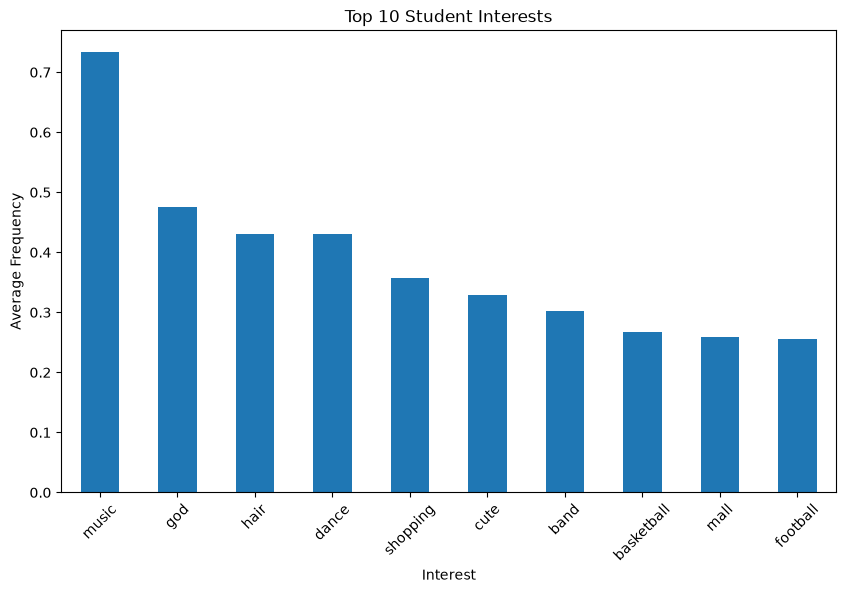

In [36]:
plt.figure(figsize=(10, 6))

interest_mean.head(10).plot(kind='bar')

plt.title('Top 10 Student Interests')
plt.xlabel('Interest')
plt.ylabel('Average Frequency')
plt.xticks(rotation=45)

plt.show()

Music has the highest average frequency among student profiles, followed by interests such as god, hair, dance, and shopping. This indicates that entertainment, lifestyle, and social interests are prominent in the dataset and may help form meaningful student clusters.

In [37]:
top5_interests = interest_mean.head(5).index

trend = df.groupby('gradyear')[top5_interests].mean()

trend

,music,god,hair,dance,shopping
gradyear,,,,,
2006,0.711247,0.474076,0.331561,0.346716,0.308429
2007,0.713674,0.490768,0.387209,0.398983,0.336366
2008,0.768804,0.480074,0.491686,0.452890,0.379520
2009,0.737678,0.454619,0.514678,0.525720,0.405063


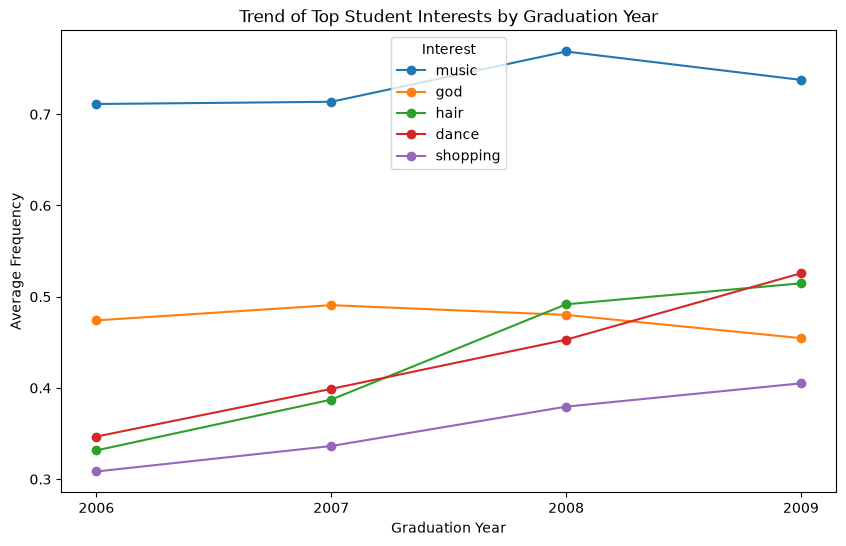

In [38]:
trend.plot(figsize=(10, 6), marker='o')

plt.title('Trend of Top Student Interests by Graduation Year')
plt.xlabel('Graduation Year')
plt.ylabel('Average Frequency')
plt.xticks([2006, 2007, 2008, 2009])
plt.legend(title='Interest')
plt.show()

From the trend plot, dance, hair, and shopping generally increase from the 2006 to 2009 graduation groups. music remains the most frequent interest throughout, while god is relatively stable before decreasing somewhat by 2009.

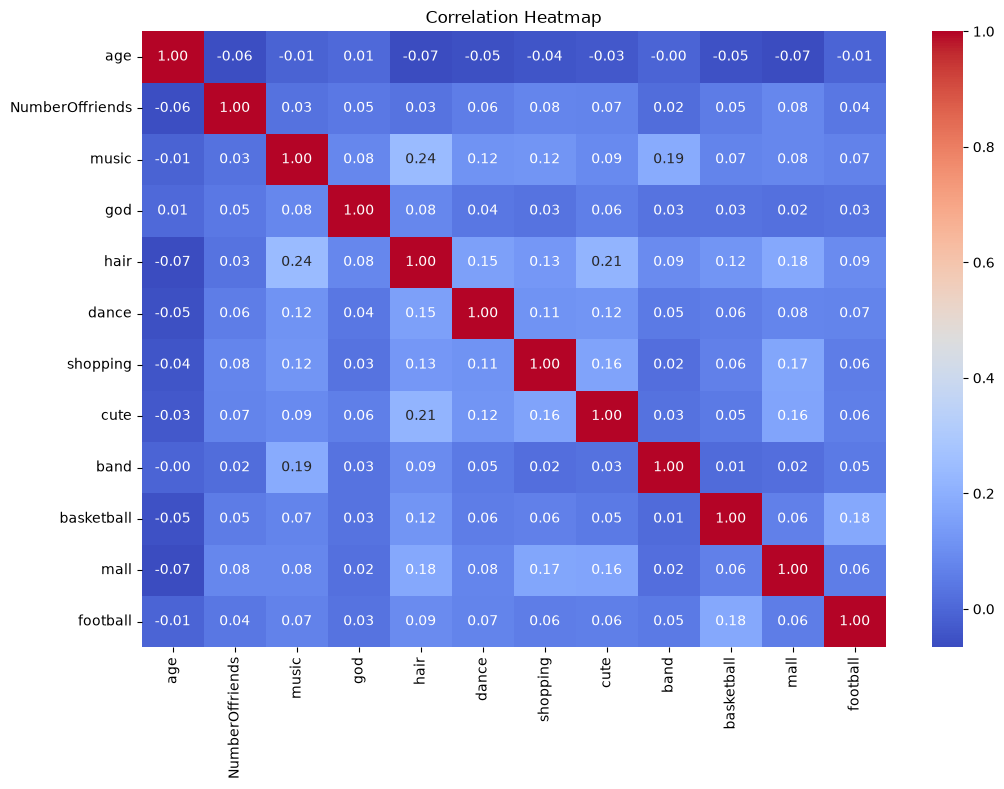

In [39]:
corr_cols = ['age', 'NumberOffriends'] + list(interest_mean.head(10).index)

plt.figure(figsize=(12, 8))

sns.heatmap(
    df[corr_cols].corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()

From the correlation heatmap, most correlations are fairly weak. For example, music–hair is about 0.24, hair–cute about 0.21, and music–band about 0.19. There is no obvious severe multicollinearity among these selected variables, which is fine for our clustering exercise.

In [40]:
#skewness
numeric_cols = df.select_dtypes(include=np.number).columns

skewness = df[numeric_cols].skew().sort_values(ascending=False)

skewness

blonde             117.250830
sex                 49.972125
bible               21.417635
jesus               19.160195
swimming            16.380904
kissed              12.866542
drugs               12.508258
marching            11.670519
god                 11.490218
tennis              11.236150
baseball             9.344208
abercrombie          8.169792
death                8.104098
softball             7.842373
hollister            7.788430
volleyball           7.548032
drunk                7.545941
band                 7.413696
soccer               7.277183
die                  6.993131
cheerleading         6.917809
sexy                 6.678510
rock                 6.450876
sports               5.877223
dance                5.728317
hot                  5.685510
basketball           5.681317
church               5.549156
dress                5.546623
mall                 4.697283
hair                 4.637419
clothes              4.572851
music                4.378561
cute      

In [41]:
skewed_cols = skewness[abs(skewness) > 1]

skewed_cols

blonde             117.250830
sex                 49.972125
bible               21.417635
jesus               19.160195
swimming            16.380904
kissed              12.866542
drugs               12.508258
marching            11.670519
god                 11.490218
tennis              11.236150
baseball             9.344208
abercrombie          8.169792
death                8.104098
softball             7.842373
hollister            7.788430
volleyball           7.548032
drunk                7.545941
band                 7.413696
soccer               7.277183
die                  6.993131
cheerleading         6.917809
sexy                 6.678510
rock                 6.450876
sports               5.877223
dance                5.728317
hot                  5.685510
basketball           5.681317
church               5.549156
dress                5.546623
mall                 4.697283
hair                 4.637419
clothes              4.572851
music                4.378561
cute      

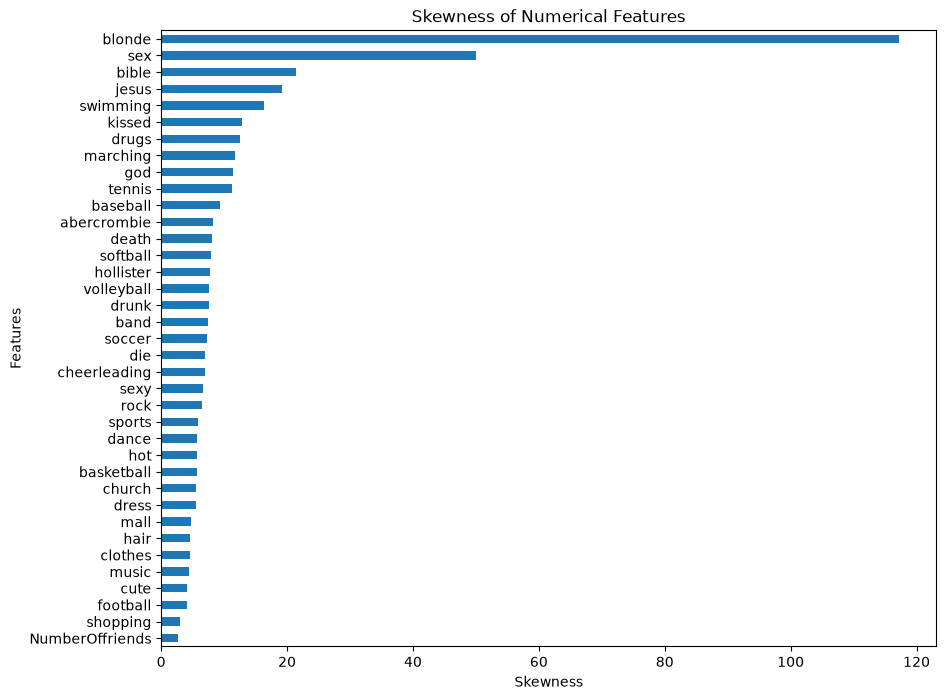

In [42]:
plt.figure(figsize=(10, 8))

skewed_cols.sort_values().plot(kind='barh')

plt.title('Skewness of Numerical Features')
plt.xlabel('Skewness')
plt.ylabel('Features')

plt.show()

Most interest-related features are highly positively skewed because they contain many zero values and relatively few high-frequency observations. Since these variables represent genuine student interests and clustering does not require normality, they are retained without transformation. NumberOffriends is also positively skewed and will be log-transformed to reduce the effect of extreme values.

In [43]:
df['NumberOffriends'] = np.log1p(df['NumberOffriends'])

In [44]:
print("Skewness after transformation:",
      df['NumberOffriends'].skew())

Skewness after transformation: -0.5349696591920687


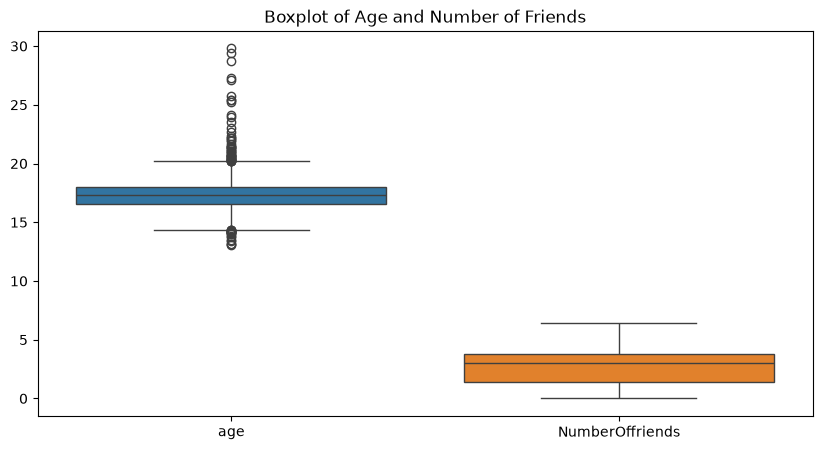

In [45]:
#check outliers
plt.figure(figsize=(10, 5))

sns.boxplot(data=df[['age', 'NumberOffriends']])

plt.title('Boxplot of Age and Number of Friends')
plt.show()

The age variable contained unrealistic values below 13 and above 30, which were treated as missing values and imputed using the median. The remaining statistical outliers were retained because they fall within a plausible age range and may represent genuine student profiles. NumberOffriends was log-transformed to reduce the effect of extreme values.

In [46]:
interest_cols = df.columns[4:]

cluster_features = ['age', 'NumberOffriends'] + list(interest_cols)

X = df[cluster_features]

X.shape

(15000, 38)

In [47]:
X.head()

,age,NumberOffriends,basketball,football,soccer,softball,volleyball,swimming,cheerleading,baseball,...,blonde,mall,shopping,clothes,hollister,abercrombie,die,death,drunk,drugs
0,17.281,0.000000,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,17.410,3.912023,0,0,1,0,0,1,0,0,...,0,0,0,0,0,0,0,0,1,0
2,17.511,3.737670,0,0,0,0,0,0,0,1,...,0,1,0,0,0,0,0,0,1,1
3,17.281,3.610918,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,16.657,0.693147,0,0,0,0,0,1,0,0,...,0,0,0,3,0,0,0,0,0,0


In [48]:
X.isnull().sum().sum()

np.int64(0)

In [49]:
#feature scaling
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [50]:
X_scaled.shape

(15000, 38)

In [51]:
print("Mean:", X_scaled.mean())
print("Standard Deviation:", X_scaled.std())

Mean: 2.7349662495748418e-17
Standard Deviation: 1.0


In [52]:
#elbow method
from sklearn.cluster import KMeans

wcss = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

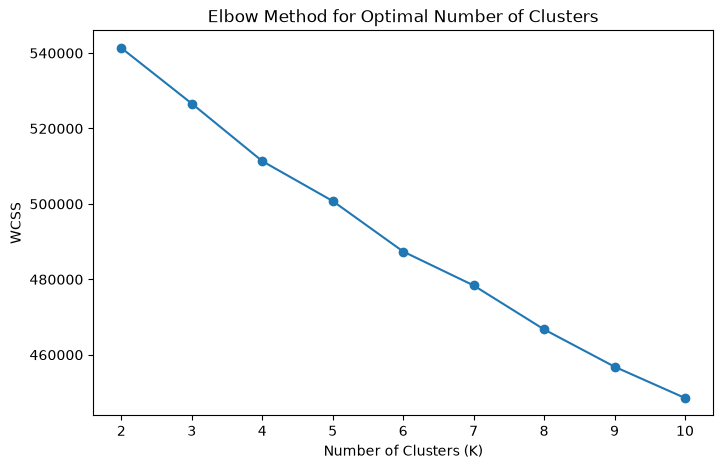

In [53]:
plt.figure(figsize=(8, 5))

plt.plot(range(2, 11), wcss, marker='o')

plt.title('Elbow Method for Optimal Number of Clusters')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')

plt.show()

In [54]:
from sklearn.metrics import silhouette_score

kmeans_silhouette = []

for k in range(2, 11):
    
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    labels = kmeans.fit_predict(X_scaled)
    
    score = silhouette_score(
        X_scaled,
        labels,
        sample_size=5000,
        random_state=42
    )
    
    kmeans_silhouette.append(score)
    
    print(f"K = {k}, Silhouette Score = {score:.4f}")

K = 2, Silhouette Score = 0.3875
K = 3, Silhouette Score = 0.2771
K = 4, Silhouette Score = 0.2765
K = 5, Silhouette Score = 0.2597
K = 6, Silhouette Score = 0.2476
K = 7, Silhouette Score = 0.0040
K = 8, Silhouette Score = 0.0022
K = 9, Silhouette Score = 0.2066
K = 10, Silhouette Score = 0.2210


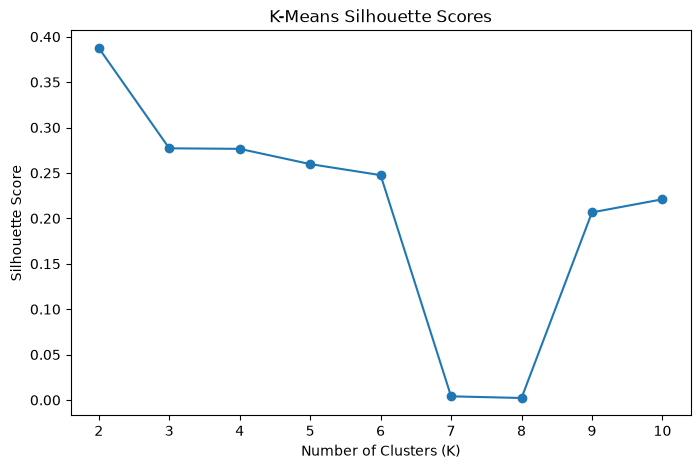

In [55]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 11),
    kmeans_silhouette,
    marker='o'
)

plt.title('K-Means Silhouette Scores')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.xticks(range(2, 11))

plt.show()

The Elbow Method did not show a distinct elbow. Therefore, silhouette scores were evaluated for different values of K. The highest silhouette score was obtained at K=2 (approximately 0.39), indicating that two clusters provide the clearest separation for the K-Means model.

In [56]:
kmeans_final = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans_final.fit_predict(X_scaled)

In [57]:
kmeans_score = silhouette_score(
    X_scaled,
    kmeans_labels,
    sample_size=5000,
    random_state=42
)

print("K-Means Silhouette Score:", kmeans_score)

K-Means Silhouette Score: 0.3875465088023735


In [58]:
pd.Series(kmeans_labels).value_counts().sort_index()

0     2279
1    12721
Name: count, dtype: int64

In [59]:
df['KMeans_Cluster'] = kmeans_labels

In [60]:
df['KMeans_Cluster'].value_counts()

KMeans_Cluster
1    12721
0     2279
Name: count, dtype: int64

In [61]:
#Hierarchical Clustering
np.random.seed(42)

sample_indices = np.random.choice(
    X_scaled.shape[0],
    size=2000,
    replace=False
)

X_sample = X_scaled[sample_indices]

In [62]:
X_sample.shape

(2000, 38)

In [63]:
from scipy.cluster.hierarchy import linkage, dendrogram

Z = linkage(X_sample, method='ward')

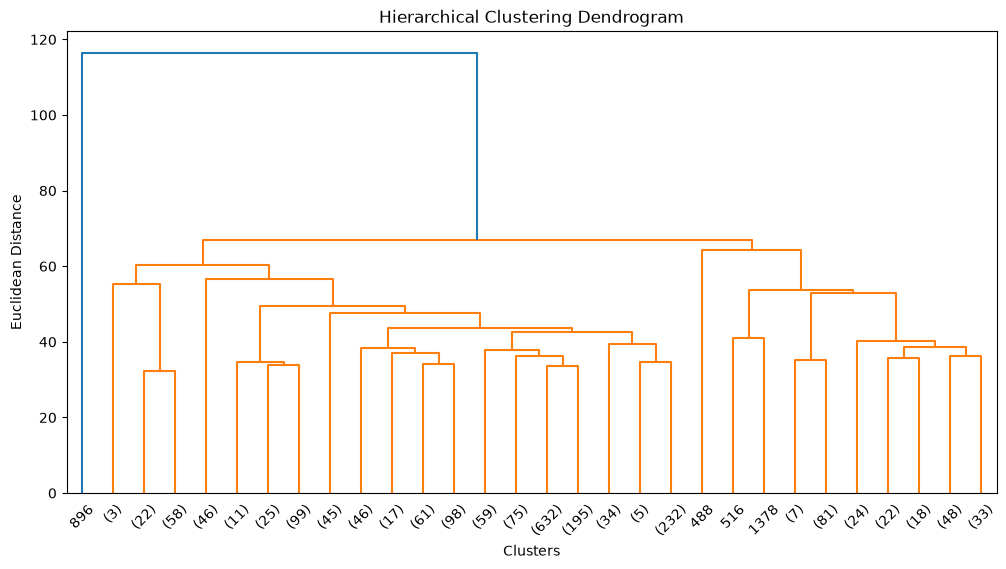

In [64]:
plt.figure(figsize=(12, 6))

dendrogram(
    Z,
    truncate_mode='lastp',
    p=30
)

plt.title('Hierarchical Clustering Dendrogram')
plt.xlabel('Clusters')
plt.ylabel('Euclidean Distance')

plt.show()

In [65]:
#Hierarchical Clustering silhouette scores
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

hierarchical_scores = []

for k in range(2, 11):
    
    hierarchical = AgglomerativeClustering(
        n_clusters=k,
        linkage='ward'
    )
    
    labels = hierarchical.fit_predict(X_sample)
    
    score = silhouette_score(X_sample, labels)
    
    hierarchical_scores.append(score)
    
    print(f"K = {k}, Silhouette Score = {score:.4f}")

K = 2, Silhouette Score = 0.9120
K = 3, Silhouette Score = 0.2889
K = 4, Silhouette Score = 0.2808
K = 5, Silhouette Score = 0.2366
K = 6, Silhouette Score = 0.2371
K = 7, Silhouette Score = 0.1977
K = 8, Silhouette Score = 0.1993
K = 9, Silhouette Score = 0.2043
K = 10, Silhouette Score = 0.1948


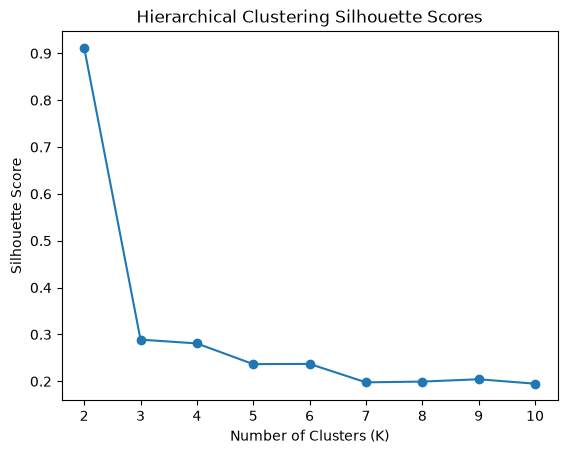

In [66]:
plt.plot(
    range(2, 11),
    hierarchical_scores,
    marker='o'
)

plt.title('Hierarchical Clustering Silhouette Scores')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.xticks(range(2, 11))

plt.show()

In [67]:
hierarchical_final = AgglomerativeClustering(
    n_clusters=2,
    linkage='ward'
)

hierarchical_labels = hierarchical_final.fit_predict(X_sample)

pd.Series(hierarchical_labels).value_counts().sort_index()

0    1999
1       1
Name: count, dtype: int64

In [68]:
hierarchical_3 = AgglomerativeClustering(
    n_clusters=3,
    linkage='ward'
)

labels_3 = hierarchical_3.fit_predict(X_sample)

pd.Series(labels_3).value_counts().sort_index()

0     236
1       1
2    1763
Name: count, dtype: int64

At K=3, Hierarchical Clustering produced two substantive clusters containing 236 and 1,763 students, along with one singleton cluster containing an extreme observation. Although the silhouette score (0.2889) is lower than K=2, K=3 provides a more informative segmentation than the highly imbalanced K=2 solution.

In [69]:
hierarchical_score = silhouette_score(X_sample, labels_3)

print("Hierarchical Silhouette Score:", hierarchical_score)

Hierarchical Silhouette Score: 0.28888985843171766


In [70]:
#DBSCAN
min_samples = 2 * X_scaled.shape[1]

min_samples

76

In [71]:
from sklearn.neighbors import NearestNeighbors

neighbors = NearestNeighbors(n_neighbors=min_samples)

neighbors_fit = neighbors.fit(X_scaled)

distances, indices = neighbors_fit.kneighbors(X_scaled)

In [72]:
distances = np.sort(distances[:, -1])

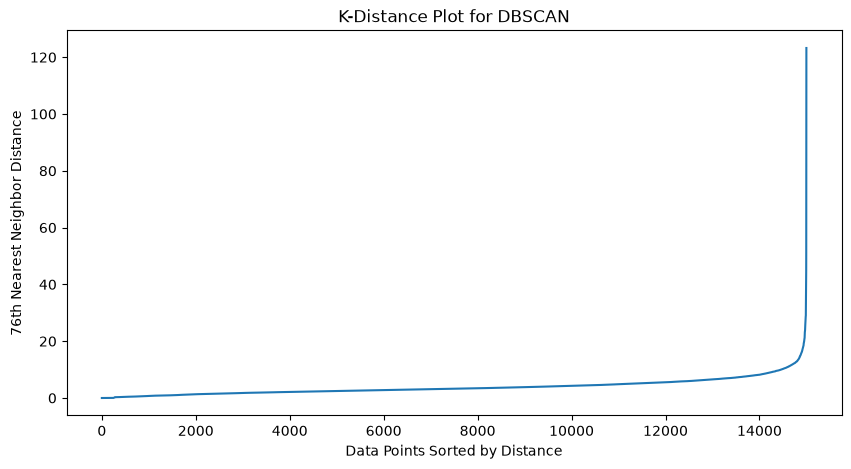

In [73]:
plt.figure(figsize=(10, 5))

plt.plot(distances)

plt.title('K-Distance Plot for DBSCAN')
plt.xlabel('Data Points Sorted by Distance')
plt.ylabel('76th Nearest Neighbor Distance')

plt.show()

In [74]:
from sklearn.cluster import DBSCAN

for eps in [8, 10, 12, 14, 16]:
    
    dbscan = DBSCAN(
        eps=eps,
        min_samples=76
    )
    
    labels = dbscan.fit_predict(X_scaled)
    
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = np.sum(labels == -1)
    
    print(
        f"eps={eps} | "
        f"Clusters={n_clusters} | "
        f"Noise Points={n_noise}"
    )

eps=8 | Clusters=1 | Noise Points=429
eps=10 | Clusters=1 | Noise Points=181
eps=12 | Clusters=1 | Noise Points=92
eps=14 | Clusters=1 | Noise Points=50
eps=16 | Clusters=1 | Noise Points=30


In [75]:
results = []

for min_samples in [5, 10, 20, 30]:
    for eps in [2, 3, 4, 5, 6, 7, 8]:

        dbscan = DBSCAN(
            eps=eps,
            min_samples=min_samples
        )

        labels = dbscan.fit_predict(X_scaled)

        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        n_noise = np.sum(labels == -1)

        results.append([
            eps,
            min_samples,
            n_clusters,
            n_noise
        ])

dbscan_results = pd.DataFrame(
    results,
    columns=[
        'eps',
        'min_samples',
        'Clusters',
        'Noise_Points'
    ]
)

dbscan_results

,eps,min_samples,Clusters,Noise_Points
0,2,5,27,7930
1,3,5,6,4696
2,4,5,6,2756
3,5,5,2,1572
4,6,5,2,945
5,7,5,1,546
6,8,5,2,349
7,2,10,15,8285
8,3,10,6,4859
9,4,10,3,2872


In [77]:
dbscan_candidates = [
    (5, 5),
    (6, 5),
    (5, 10),
    (6, 10),
    (4, 20),
    (4, 30)
]

for eps, min_samples in dbscan_candidates:
    
    dbscan = DBSCAN(
        eps=eps,
        min_samples=min_samples
    )
    
    labels = dbscan.fit_predict(X_scaled)
    
    # Exclude noise points
    mask = labels != -1
    
    cluster_labels = labels[mask]
    
    n_clusters = len(set(cluster_labels))
    
    if n_clusters >= 2:
        score = silhouette_score(
            X_scaled[mask],
            cluster_labels,
            sample_size=min(5000, mask.sum()),
            random_state=42
        )
        
        print(
            f"eps={eps}, min_samples={min_samples} | "
            f"Clusters={n_clusters} | "
            f"Noise={np.sum(labels == -1)} | "
            f"Silhouette={score:.4f}"
        )

eps=5, min_samples=5 | Clusters=2 | Noise=1572 | Silhouette=0.4026
eps=6, min_samples=5 | Clusters=2 | Noise=945 | Silhouette=0.3503
eps=5, min_samples=10 | Clusters=2 | Noise=1617 | Silhouette=0.4142
eps=6, min_samples=10 | Clusters=2 | Noise=982 | Silhouette=0.4104
eps=4, min_samples=20 | Clusters=2 | Noise=2984 | Silhouette=0.2433
eps=4, min_samples=30 | Clusters=2 | Noise=3079 | Silhouette=0.2579


In [78]:
dbscan_final = DBSCAN(
    eps=5,
    min_samples=10
)

dbscan_labels = dbscan_final.fit_predict(X_scaled)

pd.Series(dbscan_labels).value_counts().sort_index()

-1     1617
 0    13373
 1       10
Name: count, dtype: int64

In [79]:
cluster_profile = df.groupby('KMeans_Cluster')[cluster_features].mean()

cluster_profile

,age,NumberOffriends,basketball,football,soccer,softball,volleyball,swimming,cheerleading,baseball,...,blonde,mall,shopping,clothes,hollister,abercrombie,die,death,drunk,drugs
KMeans_Cluster,,,,,,,,,,,,,,,,,,,,,
0,17.073200,2.989766,0.653357,0.591487,0.426942,0.351470,0.342694,0.299693,0.315928,0.241334,...,0.470821,0.780606,0.895129,0.574375,0.297499,0.239579,0.544976,0.310224,0.322510,0.291795
1,17.322284,2.528536,0.197783,0.195268,0.185284,0.125305,0.107146,0.105495,0.067369,0.079553,...,0.048738,0.166103,0.260907,0.074287,0.031365,0.017766,0.121531,0.083641,0.050389,0.019731


In [80]:
for cluster in sorted(df['KMeans_Cluster'].unique()):
    
    print(f"\nCluster {cluster} - Top 10 Interests")
    
    top_interests = (
        df[df['KMeans_Cluster'] == cluster][interest_cols]
        .mean()
        .sort_values(ascending=False)
        .head(10)
    )
    
    print(top_interests)


Cluster 0 - Top 10 Interests
hair        1.689776
music       1.510750
dance       1.121983
god         1.086880
cute        0.941641
shopping    0.895129
sex         0.860904
mall        0.780606
band        0.683633
rock        0.681000
dtype: float64

Cluster 1 - Top 10 Interests
music         0.593585
god           0.365301
dance         0.307051
shopping      0.260907
band          0.233551
cute          0.218143
hair          0.205723
basketball    0.197783
football      0.195268
soccer        0.185284
dtype: float64


In [81]:
gender_profile = pd.crosstab(
    df['KMeans_Cluster'],
    df['gender'],
    normalize='index'
) * 100

gender_profile.round(2)

gender,F,M,Unknown
KMeans_Cluster,,,
0,86.09,8.29,5.62
1,71.50,19.00,9.50


In [82]:
gradyear_profile = pd.crosstab(
    df['KMeans_Cluster'],
    df['gradyear'],
    normalize='index'
) * 100

gradyear_profile.round(2)

gradyear,2006,2007,2008,2009
KMeans_Cluster,,,,
0,17.77,22.25,29.05,30.93
1,26.38,25.39,24.58,23.65


In [83]:
cluster_trend = pd.crosstab(
    df['gradyear'],
    df['KMeans_Cluster'],
    normalize='index'
) * 100

cluster_trend.round(2)

KMeans_Cluster,0,1
gradyear,,
2006,10.77,89.23
2007,13.57,86.43
2008,17.47,82.53
2009,18.99,81.01


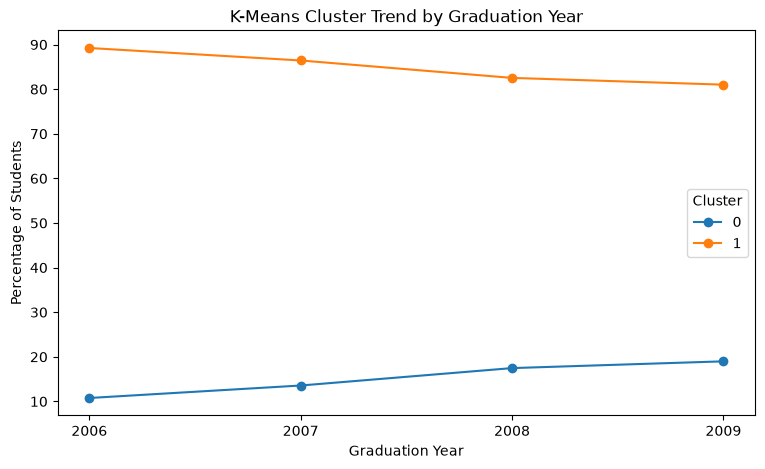

In [84]:
cluster_trend.plot(
    kind='line',
    marker='o',
    figsize=(9, 5)
)

plt.title('K-Means Cluster Trend by Graduation Year')
plt.xlabel('Graduation Year')
plt.ylabel('Percentage of Students')
plt.xticks([2006, 2007, 2008, 2009])
plt.legend(title='Cluster')
plt.show()

Trend Analysis: The proportion of students belonging to Cluster 0 increased consistently from 10.77% in 2006 to 18.99% in 2009, while the proportion belonging to Cluster 1 decreased from 89.23% to 81.01%. This indicates an increasing representation of the more interest-expressive student segment across later graduation cohorts in this dataset.

In [86]:
dbscan_final = DBSCAN(
    eps=5,
    min_samples=10
)

dbscan_labels = dbscan_final.fit_predict(X_scaled)

In [87]:
# Exclude DBSCAN noise points (-1)
mask = dbscan_labels != -1

dbscan_score = silhouette_score(
    X_scaled[mask],
    dbscan_labels[mask],
    sample_size=5000,
    random_state=42
)

print("DBSCAN Silhouette Score:", dbscan_score)

DBSCAN Silhouette Score: 0.41416420902632833


In [88]:
comparison = pd.DataFrame({
    'Clustering Method': [
        'K-Means',
        'Hierarchical',
        'DBSCAN'
    ],

    'Silhouette Score': [
        kmeans_score,
        hierarchical_score,
        dbscan_score
    ]
})

comparison

,Clustering Method,Silhouette Score
0,K-Means,0.387547
1,Hierarchical,0.288890
2,DBSCAN,0.414164


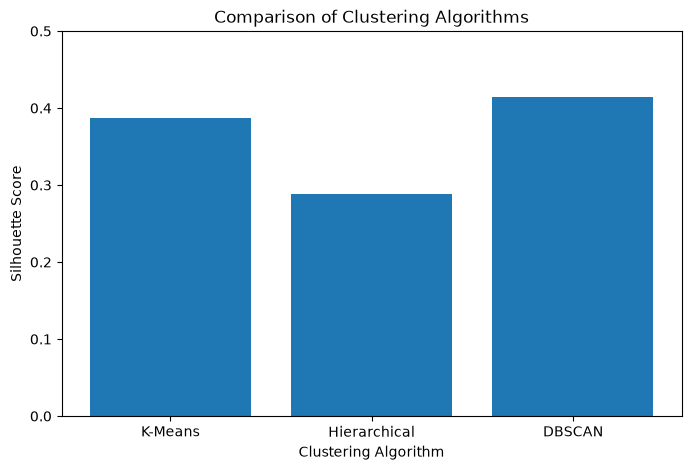

In [89]:
plt.figure(figsize=(8, 5))

plt.bar(
    comparison['Clustering Method'],
    comparison['Silhouette Score']
)

plt.title('Comparison of Clustering Algorithms')
plt.xlabel('Clustering Algorithm')
plt.ylabel('Silhouette Score')
plt.ylim(0, 0.5)

plt.show()

Observation: DBSCAN achieved the highest silhouette score (0.4142), followed by K-Means (0.3875) and Hierarchical Clustering (0.2889). However, DBSCAN produced highly imbalanced clusters and classified 1,617 observations as noise. Therefore, K-Means was selected for final student segmentation because it provided more meaningful and interpretable clusters while assigning all students to a cluster.

In [90]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(
    X_pca,
    columns=['PC1', 'PC2']
)

pca_df['Cluster'] = kmeans_labels

pca_df.head()

,PC1,PC2,Cluster
0,-1.757297,-0.083701,1
1,-0.738155,0.208638,1
2,2.666500,-0.080408,0
3,-1.537846,-0.103097,1
4,4.450369,-0.846525,0


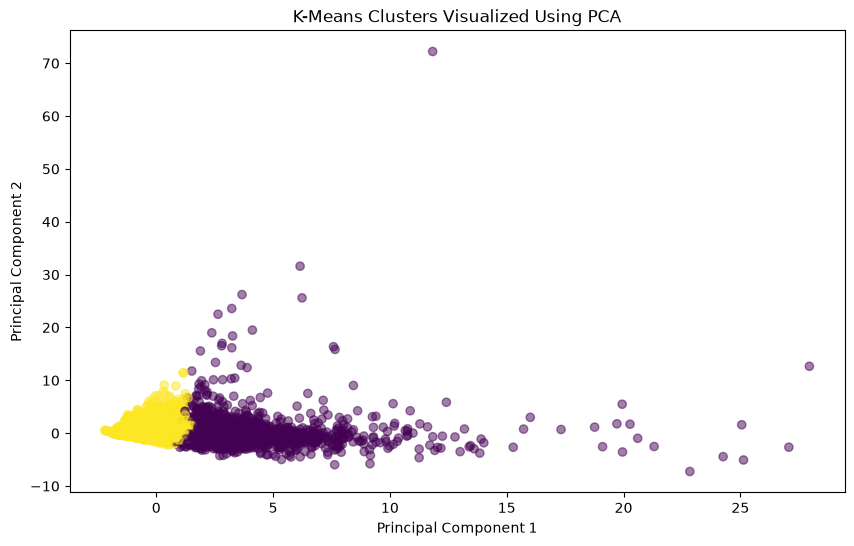

In [91]:
plt.figure(figsize=(10, 6))

plt.scatter(
    pca_df['PC1'],
    pca_df['PC2'],
    c=pca_df['Cluster'],
    alpha=0.5
)

plt.title('K-Means Clusters Visualized Using PCA')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')

plt.show()

In [92]:
print("Explained Variance Ratio:",
      pca.explained_variance_ratio_)

print("Total Explained Variance:",
      pca.explained_variance_ratio_.sum())

Explained Variance Ratio: [0.08881639 0.04735265]
Total Explained Variance: 0.1361690357529047


The first two principal components explain approximately 13.62% of the total variance (PC1 = 8.88% and PC2 = 4.74%). Therefore, the 2D PCA plot captures only a limited portion of the information present in the original multidimensional dataset. Although some separation between the K-Means clusters is visible, the PCA plot should be interpreted primarily as a visualization and not as a complete representation of the cluster structure.

K-Means with K=2 was selected for final student segmentation because it provided more useful and interpretable groups while assigning all students to a cluster. Cluster 0 represented a smaller, more interest-expressive segment, while Cluster 1 represented the larger, comparatively lower-interest-activity segment.

In [93]:
import joblib

joblib.dump(kmeans_final, 'kmeans_model.pkl')
joblib.dump(scaler, 'scaler.pkl')
joblib.dump(cluster_features, 'cluster_features.pkl')

print("Files saved successfully!")

Files saved successfully!
